# 03 — Cuisine networks from recipe ingredients

This notebook is the network-analysis part of the Social Graphs project (based on repository commit `ca8ff65`). It uses the **processed** Food.com data from notebook 02. The default run uses the 30% stratified sample (8,019 recipes), making the full workflow practical on a laptop. Set `DATASET = "full"` for the 26,727-recipe dataset.

**Research question.** Are recipes built from ingredient combinations distinctive of their cuisine more likely to be described as authentic by reviewers? This notebook produces the ingredient-network scores for that later review comparison. Its earlier cuisine-mixing analyses provide context and checks.

**Method in brief.** Conservatively standardize a small list of equivalent ingredient names; form a bipartite recipe–ingredient network and compare its ingredient cuisine distributions with shuffled labels; inspect its ingredient co-occurrence projection; project it to a recipe similarity network using Jaccard similarity; retain edges with at least two informative shared ingredients, Jaccard ≥ 0.18, and at most 15 best neighbors per recipe. Cuisine labels play no role in graph construction. Fixed-graph label permutations provide the null comparisons. Every threshold is reported below and should be varied before drawing final conclusions.

## 0. Setup and data

Run from the repository root or its `notebooks/` directory. The notebook needs `numpy`, `pandas`, `scipy`, `networkx`, `scikit-learn`, `matplotlib` and `seaborn` (all listed in the updated `requirements.txt`).

In [1]:
from pathlib import Path
import json
import heapq
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import sparse
from sklearn.metrics import adjusted_mutual_info_score

ROOT = Path.cwd()
if not (ROOT / 'data' / 'processed').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'processed').exists(), 'Run from the repository root or notebooks/'
import sys
sys.path.insert(0, str(ROOT))
DATASET = 'mini'  # 'mini' or 'full'
SEED = 42
MAX_DF_SHARE = 0.35
MIN_DF = 3
MIN_SHARED = 2
MIN_JACCARD = 0.18
CUTOFFS = (0.12, 0.18, 0.24)
TOP_K = 15
N_PERMUTATIONS = 199
FIG = ROOT / 'figures'
FIG.mkdir(exist_ok=True)

recipes = pd.read_csv(ROOT / 'data' / 'processed' / f'recipes{"_mini" if DATASET == "mini" else ""}.csv')
recipes['ingredients'] = recipes['ingredients'].map(json.loads)
assert recipes.recipe_id.is_unique and recipes.cuisine.notna().all()
print(f'{len(recipes):,} recipes, {recipes.cuisine.nunique()} cuisines')
display(recipes.cuisine.value_counts().rename('recipes').to_frame())

8,019 recipes, 9 cuisines


,recipes
cuisine,
italian,2165
mexican,1997
indian,797
french,656
greek,655
middle-eastern,582
chinese,578
thai,352
japanese,237


## 1. Ingredient normalization and audit

The raw ingredient strings include clear aliases (e.g., `garlic clove` and `garlic cloves`). This curated dictionary merges spelling, singular/plural, and a few unambiguous preparation variants. It deliberately keeps distinctions such as `ground cumin` versus `cumin seeds`, `fresh basil` versus `dried basil`, and `red onion` versus `yellow onion`. Generic seasonings and water are excluded from the projection below; named oils such as olive and sesame oil remain eligible. The network uses sets, so a repeated ingredient in a recipe contributes only once.

In [2]:
from src.ingredient_preprocessing import ALIASES, GENERIC_INGREDIENTS, normalize_ingredient

raw_lists = recipes.ingredients.tolist()
normalized = [sorted({normalize_ingredient(x) for x in row if str(x).strip()}) for row in raw_lists]
raw_frequency = Counter(x for row in raw_lists for x in set(row))
frequency = Counter(x for row in normalized for x in row)
changed = [(a, b, raw_frequency[a]) for a, b in ALIASES.items() if a in raw_frequency]
print(f'Raw ingredient names: {len(raw_frequency):,}; after mapping: {len(frequency):,}')
print(f'Recipes with duplicate aliases after normalization: {sum(len(set(row)) > len(new) for row, new in zip(raw_lists, normalized)):,}')
display(pd.DataFrame(changed, columns=['raw name', 'canonical name', 'recipe frequency']).sort_values('recipe frequency', ascending=False).head(20))

Raw ingredient names: 4,827; after mapping: 4,757
Recipes with duplicate aliases after normalization: 184


,raw name,canonical name,recipe frequency
1,garlic cloves,garlic,1732
8,tomatoes,tomato,892
11,eggs,egg,725
0,garlic clove,garlic,562
56,extra virgin olive oil,olive oil,535
4,onions,onion,503
58,ground cumin,cumin,478
43,fresh cilantro,cilantro,429
64,fresh ground black pepper,black pepper,375
45,fresh parsley,parsley,363


## 2. Bipartite matrix and recipe similarity network

Ingredients appearing in fewer than 3 recipes provide little comparative information. Those appearing in more than 35% of recipes can create nearly complete projections. We exclude both, plus a small explicit list of generic seasonings, water, and unnamed oil, before computing similarities. The 35% cutoff retains ingredients such as olive oil that help distinguish cuisines. A separate 10% cutoff check is summarized below. Isolated recipes are retained as nodes.

For retained ingredients, $J(i,j)=|I_i\cap I_j|/|I_i\cup I_j|$. A sparse matrix product counts intersections. The top-15 rule limits degree without using labels; we keep the union of the directed neighbor selections. Edge weights are Jaccard values.

In [3]:
n = len(recipes)
kept_ingredients = sorted(x for x, count in frequency.items() if MIN_DF <= count <= MAX_DF_SHARE * n and x not in GENERIC_INGREDIENTS)
ingredient_index = {x: i for i, x in enumerate(kept_ingredients)}
row_idx, col_idx = [], []
for i, row in enumerate(normalized):
    for ingredient in row:
        j = ingredient_index.get(ingredient)
        if j is not None:
            row_idx.append(i); col_idx.append(j)
B = sparse.csr_matrix((np.ones(len(row_idx), dtype=np.int8), (row_idx, col_idx)), shape=(n, len(kept_ingredients)), dtype=np.int8)
sizes = np.asarray(B.sum(axis=1)).ravel().astype(np.int32)
print(f'Bipartite matrix: {B.shape[0]:,} recipes × {B.shape[1]:,} ingredients; {B.nnz:,} links')
print(f'Excluded: {sum(x < MIN_DF for x in frequency.values()):,} rare names; {sum(x > MAX_DF_SHARE*n for x in frequency.values()):,} common names')
print(f'Generic names in stoplist: {len(GENERIC_INGREDIENTS)}; present in data: {sum(x in frequency for x in GENERIC_INGREDIENTS)}')
print(f'Recipes with fewer than 2 retained ingredients: {(sizes < 2).sum():,}')

# Work in row blocks and retain only each recipe's best neighbors in small heaps.
# This avoids materializing all candidate recipe pairs for the full dataset.
B32 = B.astype(np.int32)
heaps = {cutoff: [[] for _ in range(n)] for cutoff in CUTOFFS}
candidate_counts = {cutoff: 0 for cutoff in CUTOFFS}
for start in range(0, n, 512):
    block = (B32[start:start + 512] @ B32.T).tocoo()
    row = block.row + start
    col = block.col
    eligible = (row < col) & (block.data >= MIN_SHARED)
    row, col, count = row[eligible], col[eligible], block.data[eligible]
    similarity = count / (sizes[row] + sizes[col] - count)
    eligible = similarity >= min(CUTOFFS)
    for a, b, weight in zip(row[eligible], col[eligible], similarity[eligible]):
        a, b, weight = int(a), int(b), float(weight)
        for cutoff in CUTOFFS:
            if weight < cutoff:
                continue
            candidate_counts[cutoff] += 1
            for source, target in ((a, b), (b, a)):
                heap = heaps[cutoff][source]
                item = (weight, -target, target)  # higher weight, then lower partner id
                if len(heap) < TOP_K:
                    heapq.heappush(heap, item)
                elif item > heap[0]:
                    heapq.heapreplace(heap, item)
print('Candidate pairs by Jaccard cutoff:', candidate_counts)

Bipartite matrix: 8,019 recipes × 2,138 ingredients; 66,344 links
Excluded: 2,598 rare names; 2 common names
Generic names in stoplist: 20; present in data: 20
Recipes with fewer than 2 retained ingredients: 50


Candidate pairs by Jaccard cutoff: {0.12: 1520213, 0.18: 460544, 0.24: 121785}


In [4]:
def selected_edges(cutoff):
    # Union of directed top-K selections; one undirected edge per recipe pair.
    result = {}
    for source, heap in enumerate(heaps[cutoff]):
        for weight, _, target in heap:
            result[(min(source, target), max(source, target))] = weight
    return result

edges_by_cutoff = {cutoff: selected_edges(cutoff) for cutoff in CUTOFFS}
main_edges = edges_by_cutoff[MIN_JACCARD]
edge_export = pd.DataFrame([(int(recipes.recipe_id.iloc[a]), int(recipes.recipe_id.iloc[b]), weight) for (a, b), weight in main_edges.items()], columns=['source_recipe_id', 'target_recipe_id', 'weight'])
edge_export.to_csv(ROOT / 'data' / 'processed' / f'network_edges_{DATASET}.csv', index=False)
print(f'Saved fixed graph edges: {len(edge_export):,}')

G = nx.Graph()
G.add_nodes_from(range(n))
nx.set_node_attributes(G, dict(enumerate(recipes.cuisine.tolist())), 'cuisine')
G.add_weighted_edges_from((a, b, weight) for (a, b), weight in main_edges.items())
assert G.number_of_nodes() == n
print(f'Recipe network: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges, {nx.number_connected_components(G):,} components')
print(f'Isolates: {nx.number_of_isolates(G):,}; largest component: {len(max(nx.connected_components(G), key=len)):,} nodes')
print(f'Median degree: {np.median([degree for _, degree in G.degree()]):.0f}')

Recipe network: 8,019 nodes, 84,036 edges, 187 components
Isolates: 182; largest component: 7,829 nodes
Median degree: 18


## 2a. The bipartite network and ingredient co-occurrence

The matrix above is also the adjacency matrix of a bipartite graph: one node set contains recipes, the other contains retained ingredients, and an edge means that a recipe uses an ingredient. Before looking at recipe–recipe similarity, we measure how strongly ingredient nodes are associated with cuisines. For each ingredient we calculate the entropy of its recipe links over the nine cuisine labels, divide by $\log(9)$, then average across ingredients with weights equal to their recipe degrees. Lower values mean that a typical recipe–ingredient link belongs to an ingredient concentrated in fewer cuisines. We compare the observed average with 199 shuffles of recipe cuisine labels, keeping the bipartite edges and cuisine counts fixed. This is a label-permutation test; the later ingredient-trading null preserves cuisine-specific ingredient frequencies and therefore holds this statistic fixed by construction.

The ingredient–ingredient co-occurrence projection joins two ingredients when at least one recipe uses both. We count each pair once per recipe. To inspect examples without rare-pair noise, we rank pairs appearing together in at least 30 recipes by ingredient Jaccard similarity. This ranking is descriptive, and common ingredients can still affect it.


In [ ]:
# Direct bipartite graph: cuisine concentration of ingredient nodes.
bipartite_cuisines = sorted(recipes.cuisine.unique())
bipartite_labels = pd.Categorical(recipes.cuisine, categories=bipartite_cuisines).codes
bipartite_edges = B.tocoo()
ingredient_degree = np.asarray(B.sum(axis=0)).ravel().astype(np.int32)
recipe_degree = np.asarray(B.sum(axis=1)).ravel().astype(np.int32)
n_cuisines = len(bipartite_cuisines)

def ingredient_cuisine_entropy(labels):
    counts = np.bincount(
        bipartite_edges.col * n_cuisines + labels[bipartite_edges.row],
        minlength=len(kept_ingredients) * n_cuisines,
    ).reshape(len(kept_ingredients), n_cuisines)
    shares = counts / ingredient_degree[:, None]
    entropy = -(shares * np.log(np.maximum(shares, 1e-300))).sum(axis=1) / np.log(n_cuisines)
    return float(np.average(entropy, weights=ingredient_degree)), entropy, counts

observed_entropy, ingredient_entropy, ingredient_cuisine_counts = ingredient_cuisine_entropy(bipartite_labels)
bipartite_rng = np.random.default_rng(20261118)
null_entropy = np.array([
    ingredient_cuisine_entropy(bipartite_rng.permutation(bipartite_labels))[0]
    for _ in range(N_PERMUTATIONS)
])
entropy_p = (1 + np.count_nonzero(null_entropy <= observed_entropy)) / (N_PERMUTATIONS + 1)
bipartite_summary = pd.DataFrame([{
    'dataset': DATASET,
    'recipes': B.shape[0],
    'ingredients': B.shape[1],
    'recipe_ingredient_edges': B.nnz,
    'recipe_degree_median': float(np.median(recipe_degree)),
    'ingredient_degree_median': float(np.median(ingredient_degree)),
    'observed_weighted_entropy': observed_entropy,
    'null_mean': float(null_entropy.mean()),
    'null_025': float(np.quantile(null_entropy, 0.025)),
    'null_975': float(np.quantile(null_entropy, 0.975)),
    'lower_tail_p': entropy_p,
    'permutations': N_PERMUTATIONS,
}])
display(bipartite_summary)
bipartite_summary.to_csv(ROOT / 'data' / 'processed' / f'network_bipartite_summary_{DATASET}.csv', index=False)

# The other one-mode projection: ingredients joined by shared recipes.
ingredient_cooccurrence = (B.astype(np.int32).T @ B.astype(np.int32)).tocoo()
upper = ingredient_cooccurrence.row < ingredient_cooccurrence.col
pair_a = ingredient_cooccurrence.row[upper]
pair_b = ingredient_cooccurrence.col[upper]
pair_count = ingredient_cooccurrence.data[upper]
pair_jaccard = pair_count / (ingredient_degree[pair_a] + ingredient_degree[pair_b] - pair_count)
print(f'Ingredient co-occurrence projection: {len(pair_count):,} distinct pairs')
stable_pairs = pair_count >= 30
ingredient_pairs = pd.DataFrame({
    'ingredient_a': np.asarray(kept_ingredients)[pair_a[stable_pairs]],
    'ingredient_b': np.asarray(kept_ingredients)[pair_b[stable_pairs]],
    'shared_recipes': pair_count[stable_pairs],
    'jaccard': pair_jaccard[stable_pairs],
}).sort_values(['jaccard', 'shared_recipes'], ascending=False)
display(ingredient_pairs.head(15))
ingredient_pairs.to_csv(ROOT / 'data' / 'processed' / f'network_ingredient_pairs_{DATASET}.csv', index=False)


## 2b. Ingredient-pair distinctiveness for the review analysis

Following Ahn et al. (2011), we measure a pair's *relative prevalence*: the share of recipes in its cuisine containing that pair minus the average share in the other eight cuisines. The recipe score averages this contrast over all its retained pairs, so longer ingredient lists do not automatically score higher. We leave the scored recipe out of its own cuisine counts. A separate average over single ingredients is a baseline: pair frequencies may reflect how common their individual ingredients already are. These are signatures of **Food.com cuisine tags**, not measurements of cultural authenticity. The review analysis will test whether they align with what people call authentic.


In [ ]:
from src.cuisine_distinctiveness import score_recipes

retained_rows = [B.indices[B.indptr[i]:B.indptr[i + 1]] for i in range(n)]
recipe_distinctiveness, pair_signatures = score_recipes(
    recipes.recipe_id, recipes.cuisine, retained_rows, kept_ingredients
)
assert recipe_distinctiveness.retained_ingredients.sum() == B.nnz
score_path = ROOT / 'data' / 'processed' / f'network_recipe_distinctiveness_{DATASET}.csv'
signature_path = ROOT / 'data' / 'processed' / f'network_pair_signatures_{DATASET}.csv'
recipe_distinctiveness.to_csv(score_path, index=False)
pair_signatures.to_csv(signature_path, index=False)
print(f'Scored {recipe_distinctiveness.pair_distinctiveness.notna().sum():,} of {n:,} recipes')
display(pair_signatures.groupby('cuisine').head(3))
display(recipe_distinctiveness.groupby('cuisine')[['ingredient_distinctiveness', 'pair_distinctiveness']].median())


## 3. Cuisine mixing and permutation null

The measured share of within-cuisine edge weight is compared with a null obtained by shuffling cuisine labels over the **fixed graph**. This keeps the graph, edge weights, and cuisine counts intact. Its one-sided permutation p-value measures whether within-cuisine mixing exceeds what random labels would produce. It does not establish causality or remove selection bias in Food.com tags.

Observed weighted within-cuisine share: 0.592
Shuffled-label mean [2.5%, 97.5%]: 0.171 [0.168, 0.176]
One-sided permutation p-value: 0.0050 (199 shuffles)
Unweighted attribute assortativity: 0.497


,recipes,within_weight_share,random_label_baseline,within_to_baseline_ratio
japanese,237,0.308,0.029,10.456
french,656,0.309,0.082,3.779
middle-eastern,582,0.331,0.072,4.574
greek,655,0.389,0.082,4.765
thai,352,0.468,0.044,10.702
chinese,578,0.626,0.072,8.706
indian,797,0.640,0.099,6.442
italian,2165,0.689,0.270,2.555
mexican,1997,0.755,0.249,3.033


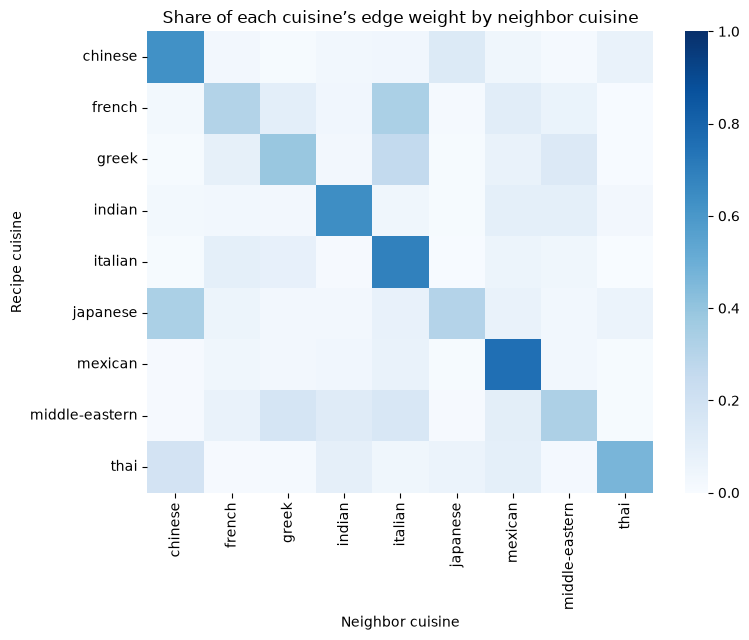

In [5]:
labels = recipes.cuisine.to_numpy()
cuisines = sorted(recipes.cuisine.unique())
cuisine_to_int = {c: i for i, c in enumerate(cuisines)}
y = np.array([cuisine_to_int[c] for c in labels], dtype=np.int16)
edges = np.array(list(G.edges()), dtype=np.int32)
u, v = edges[:, 0], edges[:, 1]
w = np.array([G[a][b]['weight'] for a, b in edges], dtype=float)
def within_weight_share(arr):
    return float(w[arr[u] == arr[v]].sum() / w.sum())

observed_within = within_weight_share(y)
rng = np.random.default_rng(SEED)
null_within = np.array([within_weight_share(rng.permutation(y)) for _ in range(N_PERMUTATIONS)])
p_within = (1 + np.count_nonzero(null_within >= observed_within)) / (N_PERMUTATIONS + 1)
assortativity = nx.attribute_assortativity_coefficient(G, 'cuisine')  # unweighted reference statistic
print(f'Observed weighted within-cuisine share: {observed_within:.3f}')
print(f'Shuffled-label mean [2.5%, 97.5%]: {null_within.mean():.3f} [{np.quantile(null_within,.025):.3f}, {np.quantile(null_within,.975):.3f}]')
print(f'One-sided permutation p-value: {p_within:.4f} ({N_PERMUTATIONS} shuffles)')
print(f'Unweighted attribute assortativity: {assortativity:.3f}')

mixing = np.zeros((len(cuisines), len(cuisines)))
np.add.at(mixing, (y[u], y[v]), w)
np.add.at(mixing, (y[v], y[u]), w)
mixing /= mixing.sum(axis=1, keepdims=True)
counts_by_cuisine = recipes.cuisine.value_counts().reindex(cuisines)
per_cuisine = pd.DataFrame({
    'recipes': counts_by_cuisine,
    'within_weight_share': np.diag(mixing),
    'random_label_baseline': (counts_by_cuisine - 1) / (n - 1),
}, index=cuisines)
per_cuisine['within_to_baseline_ratio'] = per_cuisine.within_weight_share / per_cuisine.random_label_baseline
display(per_cuisine.sort_values('within_weight_share').round(3))
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(mixing, xticklabels=cuisines, yticklabels=cuisines, cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set(title='Share of each cuisine’s edge weight by neighbor cuisine', xlabel='Neighbor cuisine', ylabel='Recipe cuisine')
fig.tight_layout()
fig.savefig(FIG / f'10_recipe_cuisine_mixing_{DATASET}.png', dpi=180)
plt.show()

## 4. Which pairs of cuisines share the cross-cuisine links?

The overall permutation above shows strong within-cuisine mixing. To compare **pairs of different cuisines**, we therefore condition on the total weight of cross-cuisine edges: each pair's statistic is its share of that cross-cuisine weight. In each of 999 label shuffles we recompute both the pair weight and the total cross-cuisine weight. The graph, weights, and cuisine counts stay fixed. The observed-to-null ratio (`lift`) measures relative cross-cuisine affinity; it does **not** mean an enriched pair has more links than it would under unrestricted random labels. Two-sided permutation p-values are adjusted across the 36 pairs using Benjamini–Hochberg. This remains an exploratory comparison conditional on the chosen graph.

Cross-cuisine edge weight: 9,700.8; 36 pairs, 999 label shuffles
Saved pair comparison: /Users/giuliadentone/Documents/Codex/2026-11-13/continuiamo-con-la-network-analysis-del/work/cuisine-networks/data/processed/network_cuisine_pairs_mini.csv


,cuisine_a,cuisine_b,observed_edge_weight,observed_cross_share,null_mean_cross_share,null_025_cross_share,null_975_cross_share,lift,difference_percentage_points,p_two_sided,q_bh,direction
4,chinese,japanese,448.389,0.046,0.005,0.004,0.006,9.008,4.109,0.002,0.002,above
19,greek,middle-eastern,617.994,0.064,0.014,0.013,0.016,4.444,4.937,0.002,0.002,above
7,chinese,thai,243.664,0.025,0.008,0.007,0.009,3.288,1.748,0.002,0.002,above
32,japanese,thai,79.694,0.008,0.003,0.003,0.004,2.626,0.509,0.002,0.002,above
10,french,italian,1329.109,0.137,0.053,0.050,0.057,2.576,8.383,0.002,0.002,above
8,french,greek,398.268,0.041,0.016,0.015,0.018,2.541,2.490,0.002,0.002,above
24,indian,middle-eastern,426.968,0.044,0.017,0.016,0.019,2.529,2.661,0.002,0.002,above
16,greek,italian,1180.711,0.122,0.053,0.050,0.057,2.284,6.842,0.002,0.002,above
13,french,middle-eastern,251.464,0.026,0.014,0.013,0.016,1.807,1.158,0.002,0.002,above
11,french,japanese,76.263,0.008,0.006,0.005,0.007,1.350,0.204,0.002,0.002,above


,cuisine_a,cuisine_b,observed_edge_weight,observed_cross_share,null_mean_cross_share,null_025_cross_share,null_975_cross_share,lift,difference_percentage_points,p_two_sided,q_bh,direction
29,italian,thai,53.710,0.006,0.029,0.026,0.032,0.193,-2.315,0.002,0.002,below
14,french,thai,18.782,0.002,0.009,0.008,0.010,0.223,-0.676,0.002,0.002,below
3,chinese,italian,126.648,0.013,0.047,0.044,0.051,0.278,-3.393,0.002,0.002,below
1,chinese,greek,38.593,0.004,0.014,0.013,0.016,0.279,-1.026,0.002,0.002,below
20,greek,thai,23.875,0.002,0.009,0.008,0.010,0.284,-0.622,0.002,0.002,below
21,indian,italian,185.819,0.019,0.065,0.061,0.069,0.296,-4.551,0.002,0.002,below
5,chinese,mexican,140.631,0.014,0.043,0.040,0.047,0.334,-2.886,0.002,0.002,below
35,middle-eastern,thai,30.631,0.003,0.008,0.007,0.009,0.410,-0.455,0.002,0.002,below


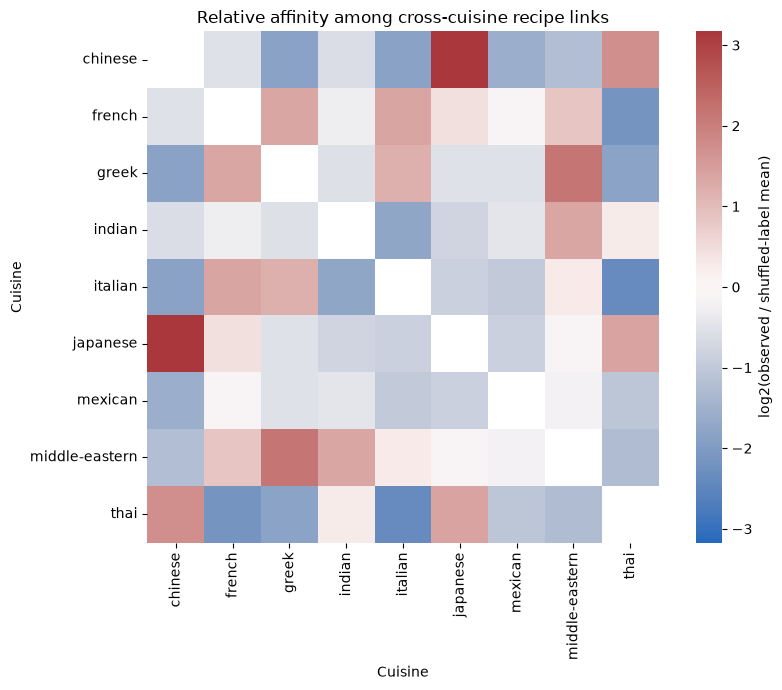

In [6]:
PAIR_PERMUTATIONS = 999
k = len(cuisines)
pair_a, pair_b = np.triu_indices(k, 1)
pair_ids = pair_a * k + pair_b

def cross_pair_shares(arr):
    left = np.minimum(arr[u], arr[v])
    right = np.maximum(arr[u], arr[v])
    mass = np.bincount(left * k + right, weights=w, minlength=k * k)[pair_ids]
    return mass, mass / mass.sum()

observed_mass, observed_pair_share = cross_pair_shares(y)
pair_rng = np.random.default_rng(SEED + 1)
null_pair_share = np.empty((PAIR_PERMUTATIONS, len(pair_ids)))
for permutation in range(PAIR_PERMUTATIONS):
    _, null_pair_share[permutation] = cross_pair_shares(pair_rng.permutation(y))
expected_pair_share = null_pair_share.mean(axis=0)
upper_p = (1 + (null_pair_share >= observed_pair_share).sum(axis=0)) / (PAIR_PERMUTATIONS + 1)
lower_p = (1 + (null_pair_share <= observed_pair_share).sum(axis=0)) / (PAIR_PERMUTATIONS + 1)
two_sided_p = np.minimum(1.0, 2 * np.minimum(upper_p, lower_p))
order = np.argsort(two_sided_p)
q_bh = np.empty_like(two_sided_p)
q_bh[order] = np.minimum.accumulate((two_sided_p[order] * len(order) / np.arange(1, len(order) + 1))[::-1])[::-1].clip(max=1)

pairs = pd.DataFrame({
    'cuisine_a': np.array(cuisines)[pair_a],
    'cuisine_b': np.array(cuisines)[pair_b],
    'observed_edge_weight': observed_mass,
    'observed_cross_share': observed_pair_share,
    'null_mean_cross_share': expected_pair_share,
    'null_025_cross_share': np.quantile(null_pair_share, .025, axis=0),
    'null_975_cross_share': np.quantile(null_pair_share, .975, axis=0),
    'lift': observed_pair_share / expected_pair_share,
    'difference_percentage_points': 100 * (observed_pair_share - expected_pair_share),
    'p_two_sided': two_sided_p,
    'q_bh': q_bh,
})
pairs['direction'] = np.where(pairs.lift > 1, 'above', 'below')
pair_path = ROOT / 'data' / 'processed' / f'network_cuisine_pairs_{DATASET}.csv'
pairs.sort_values('lift', ascending=False).to_csv(pair_path, index=False)
print(f'Cross-cuisine edge weight: {observed_mass.sum():,.1f}; 36 pairs, {PAIR_PERMUTATIONS} label shuffles')
print(f'Saved pair comparison: {pair_path}')
display(pairs.sort_values('lift', ascending=False).head(12).round(3))
display(pairs.sort_values('lift').head(8).round(3))

lift_matrix = np.full((k, k), np.nan)
lift_matrix[pair_a, pair_b] = np.log2(pairs.lift)
lift_matrix[pair_b, pair_a] = lift_matrix[pair_a, pair_b]
limit = np.nanmax(np.abs(lift_matrix))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(lift_matrix, xticklabels=cuisines, yticklabels=cuisines,
            cmap='vlag', center=0, vmin=-limit, vmax=limit,
            square=True, cbar_kws={'label': 'log2(observed / shuffled-label mean)'}, ax=ax)
ax.set(title='Relative affinity among cross-cuisine recipe links', xlabel='Cuisine', ylabel='Cuisine')
fig.tight_layout()
fig.savefig(FIG / f'12_cuisine_pair_affinity_{DATASET}.png', dpi=180)
plt.show()

## 5. Unsupervised communities

Louvain sees similarity weights but no cuisine labels. We compare its community assignments with the cuisine labels using adjusted mutual information (AMI). To assess how much alignment could occur with these group sizes alone, labels are shuffled while the detected communities stay fixed. Community modularity describes graph partition quality; AMI and the permutation null address cuisine alignment.

15 non-singleton communities; 182 isolates; weighted modularity 0.658
Cuisine/community AMI (non-isolates) 0.364; shuffled-label mean -0.000; p = 0.0050


cuisine,chinese,french,greek,indian,italian,japanese,mexican,middle-eastern,thai,total
community,,,,,,,,,,
190,490,11,4,24,8,174,22,8,248,989
132,38,173,76,105,232,23,182,112,18,959
152,7,12,8,24,24,2,820,30,21,948
95,2,82,263,12,399,10,44,59,11,882
72,9,209,103,14,393,5,54,41,2,830
59,10,5,5,555,7,1,34,95,24,736
102,4,20,21,1,601,0,12,10,3,672
40,2,10,2,5,11,2,630,0,2,664
168,1,48,114,28,150,2,74,186,6,609


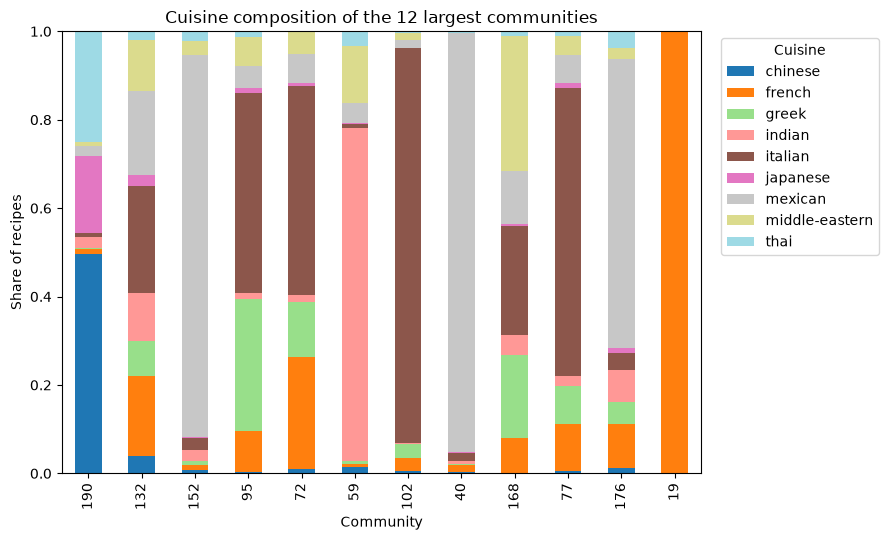

In [7]:
communities = nx.community.louvain_communities(G, weight='weight', seed=SEED)
membership = np.empty(n, dtype=np.int32)
for group_id, members in enumerate(communities):
    membership[list(members)] = group_id
modularity = nx.community.modularity(G, communities, weight='weight')
active = np.array([G.degree(i) > 0 for i in range(n)])
ami = adjusted_mutual_info_score(y[active], membership[active])
null_ami = np.array([adjusted_mutual_info_score(rng.permutation(y[active]), membership[active]) for _ in range(N_PERMUTATIONS)])
p_ami = (1 + np.count_nonzero(null_ami >= ami)) / (N_PERMUTATIONS + 1)
print(f'{sum(len(c) > 1 for c in communities)} non-singleton communities; {nx.number_of_isolates(G)} isolates; weighted modularity {modularity:.3f}')
print(f'Cuisine/community AMI (non-isolates) {ami:.3f}; shuffled-label mean {null_ami.mean():.3f}; p = {p_ami:.4f}')

composition = pd.crosstab(pd.Series(membership, name='community'), pd.Series(labels, name='cuisine'))
composition['total'] = composition.sum(axis=1)
largest = composition.nlargest(12, 'total').drop(columns='total')
display(largest.assign(total=largest.sum(axis=1)))
fig, ax = plt.subplots(figsize=(9, 5.5))
largest.div(largest.sum(axis=1), axis=0).plot(kind='bar', stacked=True, ax=ax, colormap='tab20')
ax.set(title='Cuisine composition of the 12 largest communities', xlabel='Community', ylabel='Share of recipes')
ax.legend(title='Cuisine', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
fig.savefig(FIG / f'11_community_composition_{DATASET}.png', dpi=180)
plt.show()

## 6. Recipes and ingredients connecting cuisines

For a recipe, *cross-cuisine strength* is the total Jaccard weight of edges to recipes with another cuisine. We show only nodes with at least five neighbors; this remains descriptive and favors more connected recipes. For an ingredient, cuisine reach counts the cuisines where it occurs and entropy summarizes how evenly its occurrences spread. The table requires at least 50 recipes to avoid rare-name noise. These are candidate bridges, not confirmed examples of culinary fusion.

In [8]:
cross_strength = np.zeros(n)
total_strength = np.zeros(n)
cross_count = np.zeros(n, dtype=int)
for a, b, weight in zip(u, v, w):
    total_strength[a] += weight; total_strength[b] += weight
    if y[a] != y[b]:
        cross_strength[a] += weight; cross_strength[b] += weight
        cross_count[a] += 1; cross_count[b] += 1
bridges = recipes[['recipe_id', 'name', 'cuisine']].copy()
bridges['degree'] = [G.degree(i) for i in range(n)]
bridges['cross_degree'] = cross_count
bridges['cross_strength'] = cross_strength
bridges['total_strength'] = total_strength
bridges['cross_share'] = np.divide(cross_strength, total_strength, out=np.full(n, np.nan), where=total_strength > 0)
bridges['within_share'] = 1 - bridges['cross_share']
bridges['community'] = membership
display(bridges.loc[bridges.degree >= 5].sort_values(['cross_strength', 'cross_share'], ascending=False).head(20))

metric_path = ROOT / 'data' / 'processed' / f'network_recipe_metrics_{DATASET}.csv'
bridges.to_csv(metric_path, index=False)
print(f'Saved per-recipe metrics: {metric_path}')

ingredient_rows = []
for ingredient in kept_ingredients:
    ids = B[:, ingredient_index[ingredient]].nonzero()[0]
    if len(ids) < 50:
        continue
    counts = np.bincount(y[ids], minlength=len(cuisines))
    shares = counts[counts > 0] / len(ids)
    entropy = -np.sum(shares * np.log(shares)) / np.log(len(cuisines))
    ingredient_rows.append((ingredient, len(ids), int((counts > 0).sum()), float(entropy), cuisines[int(counts.argmax())]))
ingredient_bridges = pd.DataFrame(ingredient_rows, columns=['ingredient', 'recipes', 'cuisines', 'normalized_entropy', 'most_common_cuisine'])
display(ingredient_bridges.sort_values(['cuisines', 'normalized_entropy', 'recipes'], ascending=False).head(20))

,recipe_id,name,cuisine,degree,cross_degree,cross_strength,total_strength,cross_share,within_share,community
5050,366140,green tea pound cake,japanese,148,144,62.362929,64.267691,0.970362,0.029638,132
5748,134270,mexican bunuelos,mexican,170,135,58.984855,73.161436,0.806229,0.193771,132
1165,444313,my grandmother s apple cake,french,176,134,56.686658,73.654737,0.769627,0.230373,132
989,262038,crepe batter,french,170,117,42.783089,61.813709,0.692129,0.307871,132
7226,90140,arabic salad,middle-eastern,169,119,42.280206,62.229755,0.679421,0.320579,168
4942,136457,sata andagi okinawan doughnuts,japanese,102,97,41.003372,43.104959,0.951245,0.048755,132
864,194192,simple crepes,french,132,110,39.687193,48.248304,0.822561,0.177439,132
1746,422521,eggs with tomatoes avgha me tomatoes,greek,136,115,36.372482,43.626356,0.833727,0.166273,168
1244,4313,sesame greek easter cookies koulourakia,greek,96,89,35.229897,37.982278,0.927535,0.072465,132
6171,218750,banana churros,mexican,92,77,31.939437,38.133842,0.837561,0.162439,132


Saved per-recipe metrics: /Users/giuliadentone/Documents/Codex/2026-11-13/continuiamo-con-la-network-analysis-del/work/cuisine-networks/data/processed/network_recipe_metrics_mini.csv


,ingredient,recipes,cuisines,normalized_entropy,most_common_cuisine
110,honey,240,9,0.971418,chinese
181,sugar,1173,9,0.949363,italian
23,carrot,513,9,0.933686,italian
56,cucumber,196,9,0.921246,greek
205,white wine vinegar,56,9,0.920040,italian
201,white pepper,109,9,0.919508,chinese
31,chicken,118,9,0.911864,mexican
5,baking soda,77,9,0.908893,mexican
18,brown sugar,240,9,0.902543,thai
202,white sugar,56,9,0.901849,italian


## 7. Threshold sensitivity

The graph sparsification choices affect mixing and communities. This compact check changes the Jaccard cutoff and recomputes each recipe's top-15 neighbors from the same ingredient matrix. Interpret results only if the qualitative conclusion is stable. With the audited alias map and generic-ingredient stoplist, a separate full-data run at `MAX_DF_SHARE = 0.10` found 66.8% within-cuisine edge weight, 1,245 isolates, and AMI 0.368; the 35% primary setting retains more informative ingredients and recipes.

In [9]:
sensitivity = []
for cutoff in (0.12, 0.18, 0.24):
    chosen = edges_by_cutoff[cutoff]
    if not chosen:
        continue
    su = np.fromiter((a for a, b in chosen), dtype=np.int32)
    sv = np.fromiter((b for a, b in chosen), dtype=np.int32)
    sw = np.fromiter(chosen.values(), dtype=float)
    share = sw[y[su] == y[sv]].sum() / sw.sum()
    sensitivity.append((cutoff, len(chosen), len(set(su) | set(sv)), float(share)))
display(pd.DataFrame(sensitivity, columns=['min_jaccard', 'edges', 'nonisolated_recipes', 'weighted_within_share']))

,min_jaccard,edges,nonisolated_recipes,weighted_within_share
0,0.12,90160,7882,0.587867
1,0.18,84036,7837,0.591627
2,0.24,58217,7363,0.603831


## Interpretation and limitations

- **Selection:** cuisine comes from user tags; each recipe has exactly one of nine labels after notebook 02's filtering. Tags can be broad, inconsistent, or incorrect.
- **Sampling:** `recipes_mini.csv` is stratified at 30% within each cuisine, but the nine cuisines are unequal in size. Raw bridge rankings can therefore favor larger cuisines.
- **Projection:** shared generic ingredients can dominate pair counts. The frequency filter, two-shared-ingredient minimum, similarity threshold, and top-15 cap define the graph and should all be reported.
- **Normalization:** the alias map is intentionally conservative. Remaining synonyms can undercount overlap; aggressive merging can hide real differences.
- **Inference:** permutation p-values test association conditional on this graph and these labels. They do not prove that cuisine causes ingredient choices.

**Next step for the team:** manually inspect recipes in the most distinctive cuisine pairs before interpreting them as culinary connections. Use the exported recipe pair and ingredient scores in the review/NLP analysis. Compare within cuisines, account for the number of reviews per recipe, and test whether pair scores add information beyond single-ingredient scores. An unmentioned recipe is not necessarily viewed as inauthentic.